In [15]:
from matplotlib import pyplot as plt
from analyze_critical import load, compute_observables, plot_all, extrapolate_tc, HAS_SCIPY
%matplotlib inline
from IPython.display import display

In [16]:
df_raw_obc= load("master_results_obc.csv")
df_raw_pbc= load("master_results_pbc.csv")

  Note: 329 / 484 rows have is_thermalized == 0 (retained by default).
  Note: 165 / 343 rows have is_thermalized == 0 (retained by default).


In [17]:
display(df_raw_pbc.columns)

Index(['L', 'T', 'run_tag', 'is_thermalized', 'M_abs', 'err_M_abs',
       'tau_M_abs', 'M2', 'err_M2', 'tau_M2', 'M4', 'err_M4', 'tau_M4', 'E',
       'err_E', 'tau_E', 'E2', 'err_E2', 'tau_E2', 'seed', 'N'],
      dtype='str')

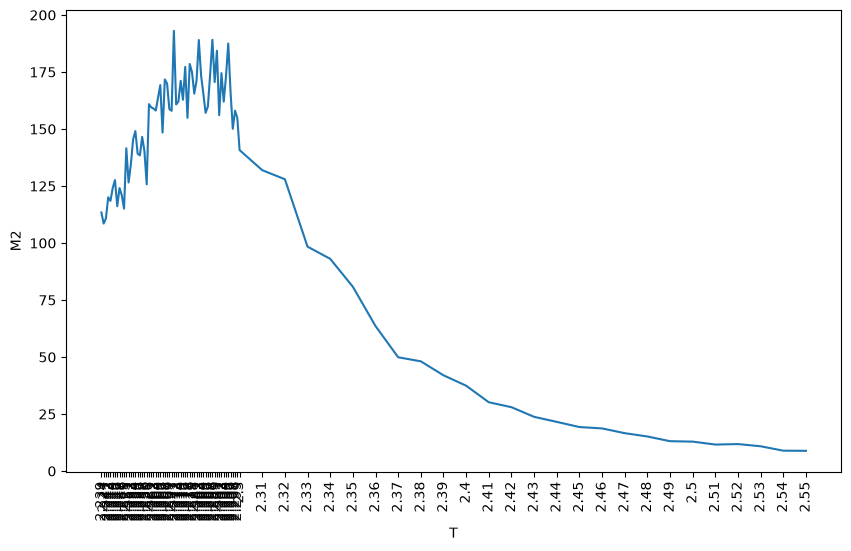

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
df_graph = df_raw_pbc[df_raw_pbc["L"] == 64].sort_values("T")
ax.plot(df_graph["T"], df_graph["tau_M2"])
ax.set_xlabel("T")
# set ticks to be at the same position as the data points
ax.set_xticks(df_graph["T"])
ax.set_xticklabels(df_graph["T"], rotation=90)
ax.set_ylabel("M2")
plt.show()

In [19]:
# prune outliers
df_raw_obc = df_raw_obc[~((df_raw_obc["L"] == 1024) & (df_raw_obc["T"].isin([2.11, 2.12, 2.15, 2.19, 2.22, 2.23])))]
df_raw_obc = df_raw_obc[~((df_raw_obc["L"] == 512) & (df_raw_obc["T"].isin([2.20, 2.11])))]
df_raw_pbc = df_raw_pbc[~((df_raw_pbc["L"] == 1024) & (df_raw_pbc["T"].isin([2.251, 2.253, 2.253, 2.258])))]

In [20]:
display(df_raw_pbc[df_raw_pbc["L"] == 1024].sort_values("T"))

,L,T,run_tag,is_thermalized,M_abs,err_M_abs,tau_M_abs,M2,err_M2,tau_M2,...,err_M4,tau_M4,E,err_E,tau_E,E2,err_E2,tau_E2,seed,N
263,1024,2.249,crit_run1,1,708928.651034,85.628476,710.87,5.026829e+11,1.202170e+08,702.02,...,1.186385e+20,685.01,-1.536323e+06,10.401084,100.30,2.360300e+12,3.195283e+07,100.27,2991649218,1048576
267,1024,2.250,crit_run1,1,704337.779149,96.132074,791.51,4.962084e+11,1.340561e+08,782.59,...,1.305236e+20,765.09,-1.534165e+06,11.045251,111.33,2.353673e+12,3.388446e+07,111.29,4288004647,1048576
275,1024,2.252,crit_run1,1,694581.038522,291.297493,3679.21,4.826734e+11,3.412894e+08,3053.71,...,2.564564e+20,2207.25,-1.529808e+06,13.620956,164.44,2.340323e+12,4.164931e+07,164.25,1570257737,1048576
282,1024,2.254,crit_run1,1,684416.978612,134.411612,1051.84,4.685983e+11,1.813198e+08,1034.51,...,1.654911e+20,1002.21,-1.525332e+06,13.443446,155.42,2.326650e+12,4.100267e+07,155.37,3208259476,1048576
286,1024,2.255,crit_run1,1,678724.423376,144.113275,1108.12,4.608542e+11,1.935945e+08,1096.99,...,1.750036e+20,1074.55,-1.523034e+06,14.472829,177.26,2.319645e+12,4.407743e+07,177.21,1319207153,1048576
290,1024,2.256,crit_run1,1,672367.088954,179.674916,1423.53,4.523042e+11,2.373257e+08,1397.25,...,2.078320e+20,1347.82,-1.520691e+06,15.733124,205.95,2.312513e+12,4.783887e+07,205.86,2021175506,1048576
294,1024,2.257,crit_run1,1,666382.469043,183.145584,1405.21,4.443042e+11,2.401069e+08,1381.65,...,2.070630e+20,1336.22,-1.518352e+06,16.685335,228.47,2.305405e+12,5.065513e+07,228.36,1956094144,1048576
301,1024,2.259,crit_run1,1,651520.786306,257.161721,1943.16,4.248196e+11,3.277765e+08,1904.10,...,2.676597e+20,1828.73,-1.513479e+06,19.364723,295.41,2.290631e+12,5.860093e+07,295.28,2290313457,1048576
305,1024,2.260,crit_run1,1,643226.925791,271.591551,1954.98,4.141181e+11,3.424308e+08,1921.64,...,2.735994e+20,1855.91,-1.510938e+06,20.548784,327.04,2.282947e+12,6.207906e+07,326.89,3289528460,1048576
309,1024,2.261,crit_run1,1,633701.866929,371.506879,2717.81,4.020858e+11,4.558271e+08,2643.43,...,3.464116e+20,2503.24,-1.508368e+06,23.934073,430.16,2.275186e+12,7.217468e+07,429.87,1039017775,1048576


In [21]:
df_obc = compute_observables(df_raw_obc)
df_pbc = compute_observables(df_raw_pbc)
#display(df_obc)

In [22]:
result_obc = extrapolate_tc(df_obc)
result_pbc = extrapolate_tc(df_pbc)
display(result_obc)
display(result_pbc)

{'chi_peak': ExtrapResult(method='χ peak FSS', Tc=2.268476 ± 0.000927),
 'cv_peak': ExtrapResult(method='Cv peak FSS', Tc=2.267194 ± 0.000453),
 'binder': ExtrapResult(method='Binder crossing (weighted mean + drift fit)', Tc=2.270021 ± 0.000408),
 'combined': ExtrapResult(method='Combined (inverse-variance weighted)', Tc=2.268729 ± 0.000288)}

{'chi_peak': ExtrapResult(method='χ peak FSS', Tc=2.269858 ± 0.000368),
 'cv_peak': ExtrapResult(method='Cv peak FSS', Tc=2.270053 ± 0.000991),
 'binder': ExtrapResult(method='Binder crossing (weighted mean + drift fit)', Tc=2.269350 ± 0.000176),
 'combined': ExtrapResult(method='Combined (inverse-variance weighted)', Tc=2.269460 ± 0.000157)}

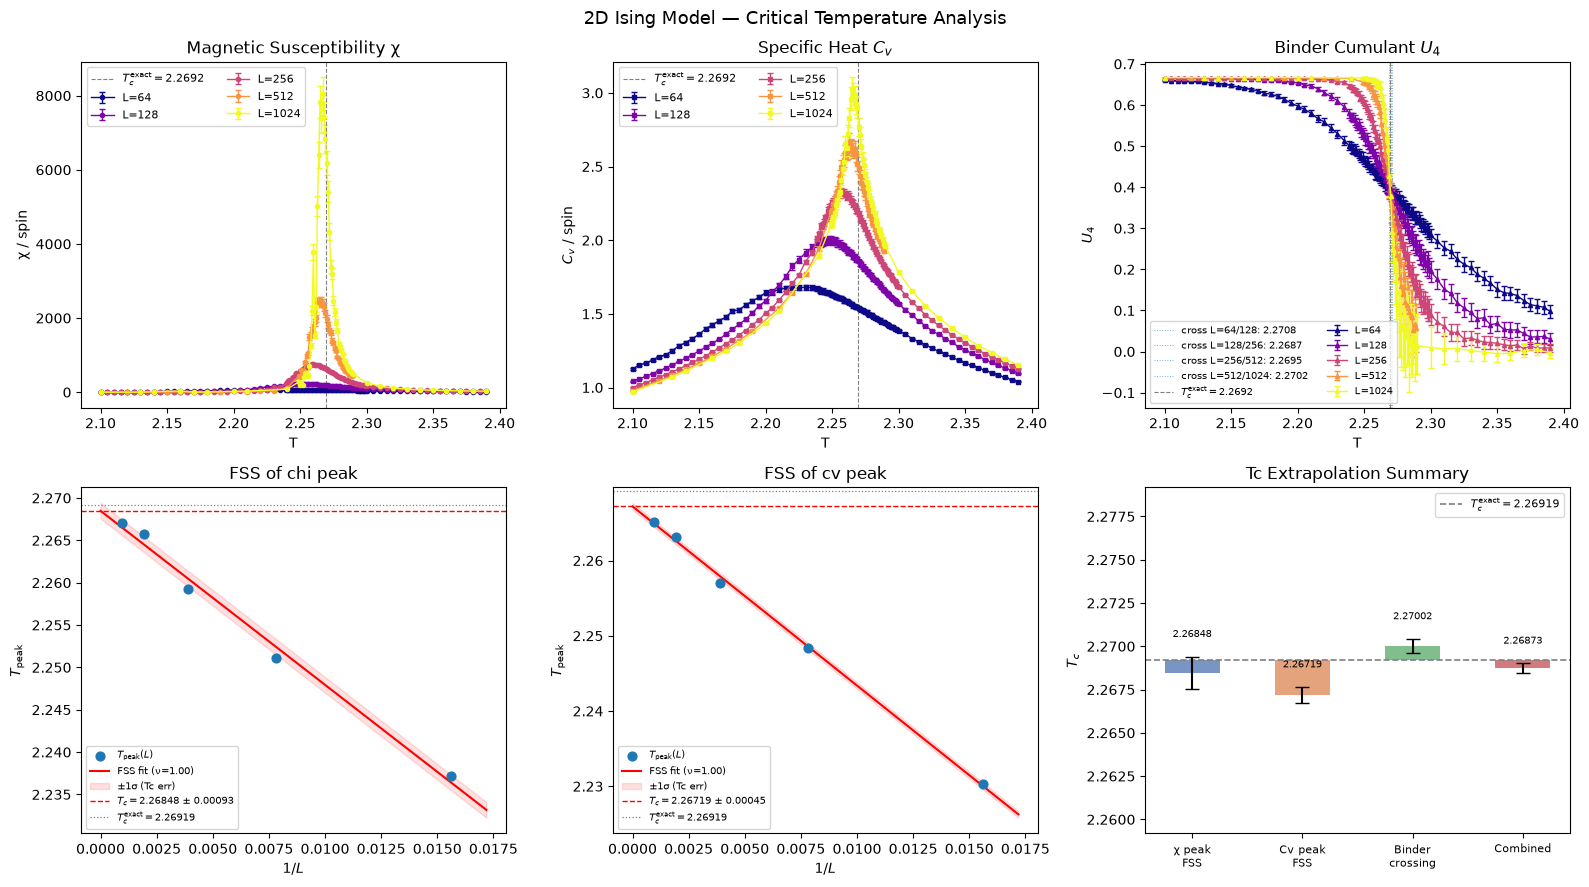

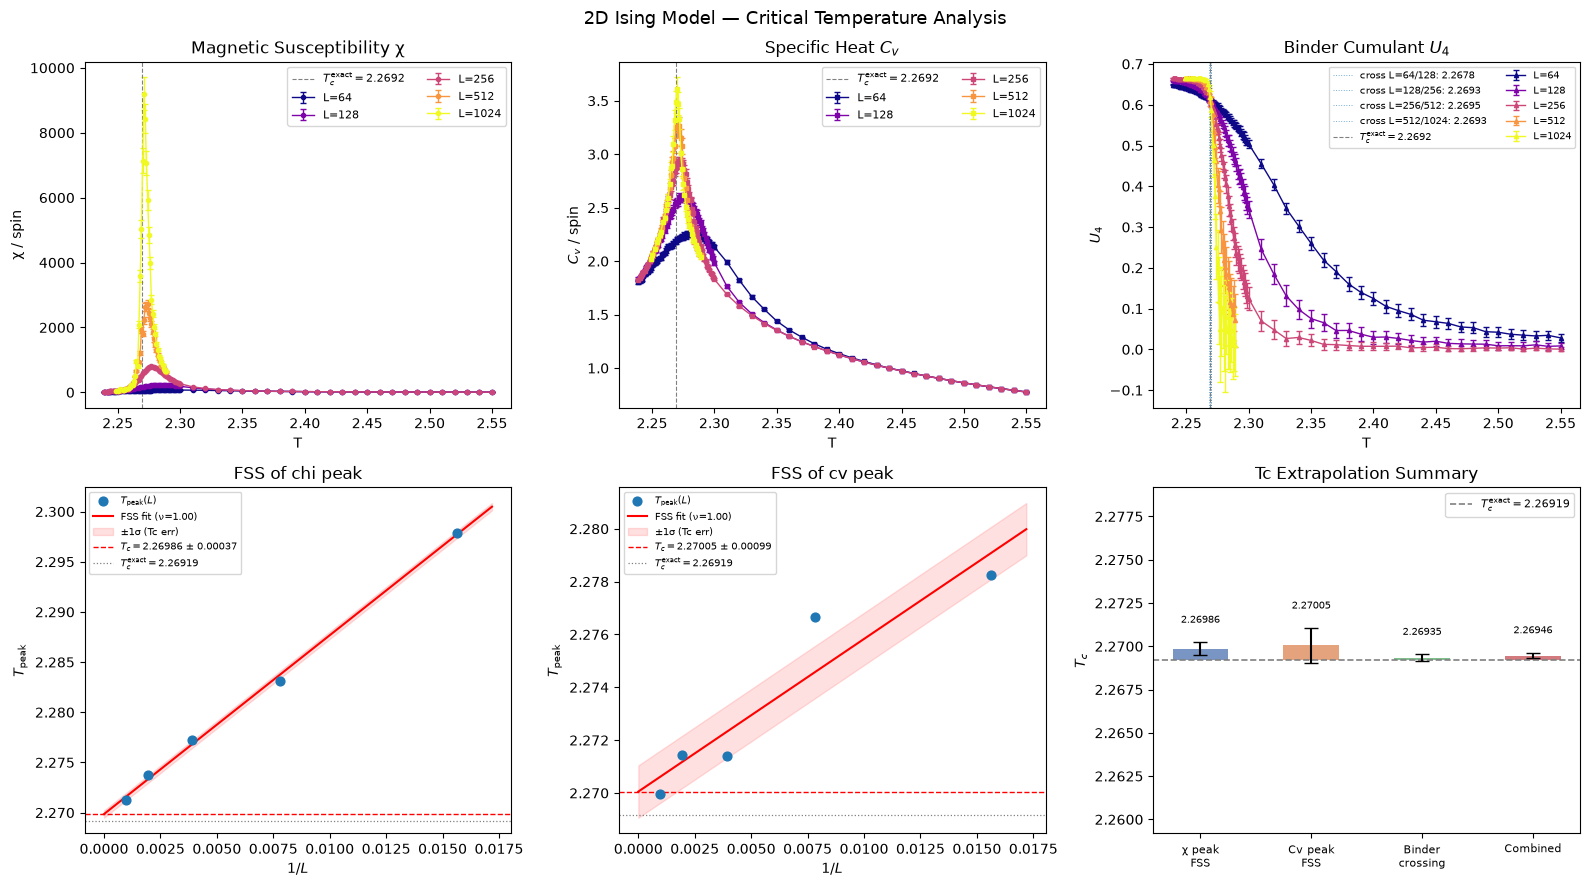

In [23]:
fig_obc = plot_all(df_obc, extrap=result_obc)
fig_pbc = plot_all(df_pbc, extrap=result_pbc)